# Naive Bayes

Here is an example to understand it. Let´s say you are a member of the Secret Service and you have been deployed to protect the Democratic presidential nominee during one of his/her campagin speeches. Being a public event that is open to all, your job is not easy and you have to be on the constant lookout for threats. So one place to start is to put a certain threat-factor for each person. So based on the features of an individual, like age, sex and other small factors like is the person carrying a bag?, does the person look nervous?, you can make a judgement call as to if that person is viable threat.

Bayes theorem works in the same way as we are computing the probability of an event(a person being a threat) based on the probabilities of certain related events(age, sex, presence of bag...).


## 1.1 Understanding our dataset

In [2]:
import pandas as pd 

df = pd.read_table('SMSSpamCollection.txt', sep='\t', header=None, names=['label', 'sms_message'])

df.head(5)

,label,sms_message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


## 1.2 Data Preprocessing
We have to convert our labels to binary variables:
- 0 = ham
- 1 = spam

We will use map for this:

In [3]:
df['label'] = df.label.map({'ham':0, 'spam':1})
df.head(5)

,label,sms_message
0,0,"Go until jurong point, crazy.. Available only ..."
1,0,Ok lar... Joking wif u oni...
2,1,Free entry in 2 a wkly comp to win FA Cup fina...
3,0,U dun say so early hor... U c already then say...
4,0,"Nah I don't think he goes to usf, he lives aro..."


## 2.1 Bag of words
Now we will convert a collection of documents to a matrix, with each document being a row and each word(token) being the column, and the corresponding(row, column) values being the frequency of occurrance of each word or token in document

Our documents:

['Hello, how are you!', 'Win money, win from home.', 'Call me now', 'Hello, Call you tomorrow?']

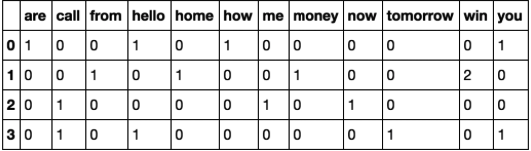


## 2.2 Implementing Bag of Words from scratch

### Convert all strings to their lower case form.

In [4]:
documents = ['Hello, how are you!',
             'Win money, win from home.',
             'Call me now.',
             'Hello, Call hello you tomorrow?']

lower_case_documents = []
for i in documents:
    lower_case_documents.append(i.lower())
print(lower_case_documents)

['hello, how are you!', 'win money, win from home.', 'call me now.', 'hello, call hello you tomorrow?']


### Removing all punctuations

In [5]:
import string
sans_punctuation_documents = []

for i in lower_case_documents:
    sans_punctuation_documents.append(i.translate(str.maketrans('','', string.punctuation)))
print(sans_punctuation_documents)

['hello how are you', 'win money win from home', 'call me now', 'hello call hello you tomorrow']


### Tokenization

In [6]:
preprocessed_documents = []
for i in sans_punctuation_documents:
    preprocessed_documents.append(i.split(' '))
print(preprocessed_documents)

[['hello', 'how', 'are', 'you'], ['win', 'money', 'win', 'from', 'home'], ['call', 'me', 'now'], ['hello', 'call', 'hello', 'you', 'tomorrow']]


### Count frequencies

In [7]:
import pprint
from collections import Counter

frequency_list = []

for i in preprocessed_documents:
    frequency_counts = Counter(i)
    frequency_list.append(frequency_counts)
pprint.pprint(frequency_list)

[Counter({'hello': 1, 'how': 1, 'are': 1, 'you': 1}),
 Counter({'win': 2, 'money': 1, 'from': 1, 'home': 1}),
 Counter({'call': 1, 'me': 1, 'now': 1}),
 Counter({'hello': 2, 'call': 1, 'you': 1, 'tomorrow': 1})]


### Implementing Bag of Words in scikit-learn

In [8]:
documents = ['Hello, how are you!',
                'Win money, win from home.',
                'Call me now.',
                'Hello, Call hello you tomorrow?']

In [9]:
from sklearn.feature_extraction.text import CountVectorizer
count_vector = CountVectorizer()

### Data preprocessing with CountVectorizer

In [10]:
count_vector.fit(documents)
count_vector.get_feature_names_out()

array(['are', 'call', 'from', 'hello', 'home', 'how', 'me', 'money',
       'now', 'tomorrow', 'win', 'you'], dtype=object)

### Create matrix with the rows being each of the 4 documents, and the columns being each word

In [11]:
doc_array = count_vector.transform(documents).toarray()
doc_array

array([[1, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 1],
       [0, 0, 1, 0, 1, 0, 0, 1, 0, 0, 2, 0],
       [0, 1, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0],
       [0, 1, 0, 2, 0, 0, 0, 0, 0, 1, 0, 1]])

### Convert the array into dataframe

In [12]:
frequency_matrix = pd.DataFrame(doc_array,
                                columns = count_vector.get_feature_names_out())
frequency_matrix

,are,call,from,hello,home,how,me,money,now,tomorrow,win,you
0,1,0,0,1,0,1,0,0,0,0,0,1
1,0,0,1,0,1,0,0,1,0,0,2,0
2,0,1,0,0,0,0,1,0,1,0,0,0
3,0,1,0,2,0,0,0,0,0,1,0,1


# Training and testing sets

- X_train = training data 'sms_message' column
- y_train = training data 'label' column
- X_test = testing data 'sms_message' column
- y_test = testing data 'label' column

In [13]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(df['sms_message'],
                                                    df['label'],
                                                    random_state=1)


## Applying Bag of Words processing to our dataset

- We have to fit our training data (X_train) into CountVectorizer() and return the matrix
- We have to transform our testing data (X_test) to return matrix

In [14]:
count_vector = CountVectorizer()

# Training data 
training_data = count_vector.fit_transform(X_train)

# Testing data
testing_data = count_vector.transform(X_test)

## Bayes Theroem implemntation from scratch

In [17]:
# P(D)
p_diabetes = 0.01

# P(-D)
p_no_diabetes = 0.99

# Sensitivity or P(Pos|D)
p_pos_diabetes = 0.9

# Specificity or P(Neg|-D)
p_neg_no_diabetes = 0.9

# P(Pos)
p_pos = (p_diabetes * p_pos_diabetes) + (p_no_diabetes * (1 - p_neg_no_diabetes))
print(f'Probability of getting a positive test result {format(p_pos)}')

Probability of getting a positive test result 0.10799999999999998


# Naive Bayes implementation using scikit-learn

In [19]:
from sklearn.naive_bayes import MultinomialNB
naive_bayes = MultinomialNB()
naive_bayes.fit(training_data, y_train)

MultinomialNB()

In [20]:
predictions = naive_bayes.predict(testing_data)

# Evaluating our model

In [22]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

print(f'Accuracy: {format(accuracy_score(y_test, predictions))}')
print(f'Precision: {format(precision_score(y_test, predictions))}')
print(f'Recall: {format(recall_score(y_test, predictions))}')
print(f'F1 Score: {format(f1_score(y_test, predictions))}')
print(f'Confusion Matrix: {format(confusion_matrix(y_test, predictions))}')

Accuracy: 0.9885139985642498
Precision: 0.9720670391061452
Recall: 0.9405405405405406
F1 Score: 0.9560439560439562
Confusion Matrix: [[1203    5]
 [  11  174]]


# Example:

In [24]:
sms = ['ur records indicate your Pension is under performing to see higher growth and up to 25% '
       'cash release reply PENSION for a free review. To opt out reply STOP',
       'This is mum, please call me back.']

sms_data = count_vector.transform(sms)
prediction = naive_bayes.predict(sms_data)
pd.Series(prediction).map({0: 'ham', 1: 'spam'})

0    spam
1     ham
dtype: object